<a href="https://colab.research.google.com/github/JasonLou622/Hospital-readmissions-analysis/blob/main/diabetes_readmission_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import pandas as pd, sqlite3 # pandas works with tables
                             # sqlite 3 lets Python talk to a SQL database.
                             # (My question is why sqlite3. I mean I saw more
                             # data analysts use PostgreSQL and MySQL than
                             # SQLite.)

df = pd.read_csv("diabetic_data.csv") # dataframe AS df
# reads the csv file into Python as a table called df.

print(df.shape) # df.shape gives (rows, columns)
df.info()       # info() lists each column with its count of non-empty values
                # and its type.
                # 'object' means text, 'int64' means whole numbers.

(101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int

Notes:
1. 'max_glu_serum' has only 5346 values and 'A1Cresult' only 17,018, out of 101,766 rows. Most of those tests are missing.

In [33]:
conn = sqlite3.connect("diabetes.db")
# creates a small database file and opens a connection to it.

df.to_sql("diabetes_data", conn, if_exists="replace", index=False)
# df as a table datebase.
# copies the table from diabetes_data.csv into the database df as a SQL table
# name as diabetes_data
# conn is like a phone line used to talk to the database.
# 3rd one means overwritte
# 'index=False' means don't add an extra row-number column

print(pd.read_sql("SELECT * FROM diabetes_data LIMIT 5", conn))
# pd.read_sql a pandas function
# use and run the context in the double quotes as a snippet of SQL code
# conn, connects to the table in diabetes.db

   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...          No      No                   No

Notes:
1. The column 'weight' shows '?' in the column 'weight'. The dataset uses '?' for missing values.

In [34]:
# Analysis 1: Measures the total number of patients were readmitted in under 30 days
query = """
SELECT readmitted, COUNT(*) AS encounters
FROM diabetes_data
GROUP BY readmitted;
"""
print(pd.read_sql(query, conn))


# In the triple quotes, allowing to write a multi-line piece of text.
# Python holds it as a text (doesn’t understand it as SQL.)
# 'pd.read_sql' sends that text through the connection, runs it,
# and brings the answer back as a table as the following.

  readmitted  encounters
0        <30       11357
1        >30       35545
2         NO       54864


Notes:
1. Readmissions: 11,357 encounters ('<30', about 11%) were followed by a readmission within 30 days, 35,545 after 30 days('>30', about 35%), and 54,864 not at all ('NO', about 54%). The three add up to 101,766, so nothing was lost.

In [35]:
# Analysis 2: Examines the average time in hospital for each age group
query = '''
SELECT age,
       COUNT(*) AS encounters,
       ROUND(AVG(time_in_hospital), 2) AS Average_time_in_hospital
FROM diabetes_data
GROUP BY age;
'''
print(pd.read_sql(query, conn))

        age  encounters  Average_time_in_hospital
0    [0-10)         161                      2.55
1   [10-20)         691                      3.19
2   [20-30)        1657                      3.56
3   [30-40)        3775                      3.80
4   [40-50)        9685                      4.04
5   [50-60)       17256                      4.13
6   [60-70)       22483                      4.38
7   [70-80)       26068                      4.59
8   [80-90)       17197                      4.81
9  [90-100)        2793                      4.76


Notes:
1. Found that average hospital stay rises with age, from about 2.5 to 4.8 days.

In [36]:
# Analysis 3: Measures the number of patients in each age group were readmitted within 30 days.
query = '''
SELECT age,
       COUNT(readmitted) AS encounters_readmitted_30d
FROM diabetes_data
WHERE readmitted = '<30'
GROUP BY age;
'''
print(pd.read_sql(query, conn))

        age  encounters_readmitted_30d
0    [0-10)                          3
1   [10-20)                         40
2   [20-30)                        236
3   [30-40)                        424
4   [40-50)                       1027
5   [50-60)                       1668
6   [60-70)                       2502
7   [70-80)                       3069
8   [80-90)                       2078
9  [90-100)                        310


Notes:
1. Age group [70-80] has the most encounters followed by a readmission within 30 days (3,069), but it is also the largest group (26,068 encounters), so the rate is a faier comparison than the count.

        age  encounters  readmitted_30d  pct_readmitted_30d
0    [0-10)         161               3                 1.9
1   [10-20)         691              40                 5.8
2   [20-30)        1657             236                14.2
3   [30-40)        3775             424                11.2
4   [40-50)        9685            1027                10.6
5   [50-60)       17256            1668                 9.7
6   [60-70)       22483            2502                11.1
7   [70-80)       26068            3069                11.8
8   [80-90)       17197            2078                12.1
9  [90-100)        2793             310                11.1


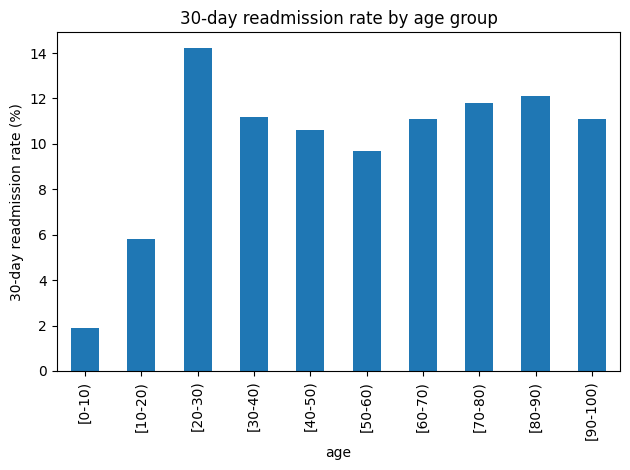

In [37]:
# Analysis 4: Determination in which age group has the highest 30-day readmission rate.
query = '''
SELECT
  age,
  COUNT(*) AS encounters,
  SUM(1) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
  ROUND(
        (SUM(1) FILTER (WHERE readmitted = '<30')) * 100.0 /
        COUNT(*),
  1) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY age
ORDER BY age;
'''
print(pd.read_sql(query, conn))

import matplotlib.pyplot as plt
result = pd.read_sql(query, conn)
result.plot(x="age", y="pct_readmitted_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("30-day readmission rate by age group")
plt.tight_layout()
plt.show()

Notes:
1. The lowest percentage of readmitted in 30 days is followed by age group [0-10], and the highest comes from age group [20-30].
2. The most common percentage of 30-day readmission by age is around 11.1%. Overall, the pct_readmitted_30d peaks is relatively smooth which indicates common expectation percentage of readmission within 30 days by age group is under 15%.

In [38]:
# Determination of readmission above 30 days
query = '''
SELECT age,
       COUNT(*) AS encounters,
       SUM(1) FILTER (WHERE readmitted = '>30') AS readmitted_over30d,
       ROUND(
             SUM(1) FILTER (WHERE readmitted = '>30') * 100.0 /
             COUNT(*),
       1) AS pct_readmitted_over30d
FROM diabetes_data
GROUP BY age
ORDER BY age;
'''

print(pd.read_sql(query, conn))

        age  encounters  readmitted_over30d  pct_readmitted_over30d
0    [0-10)         161                  26                    16.1
1   [10-20)         691                 224                    32.4
2   [20-30)        1657                 510                    30.8
3   [30-40)        3775                1187                    31.4
4   [40-50)        9685                3278                    33.8
5   [50-60)       17256                5917                    34.3
6   [60-70)       22483                7897                    35.1
7   [70-80)       26068                9475                    36.3
8   [80-90)       17197                6223                    36.2
9  [90-100)        2793                 808                    28.9


As expected, the percentage of readmission over 30 days for each group is similar to above (readmission under 30 days).


        age  encounters  readmitted_count  pct_readmitted_in_total
0    [0-10)         161                29                     18.0
1   [10-20)         691               264                     38.2
2   [20-30)        1657               746                     45.0
3   [30-40)        3775              1611                     42.7
4   [40-50)        9685              4305                     44.5
5   [50-60)       17256              7585                     44.0
6   [60-70)       22483             10399                     46.3
7   [70-80)       26068             12544                     48.1
8   [80-90)       17197              8301                     48.3
9  [90-100)        2793              1118                     40.0


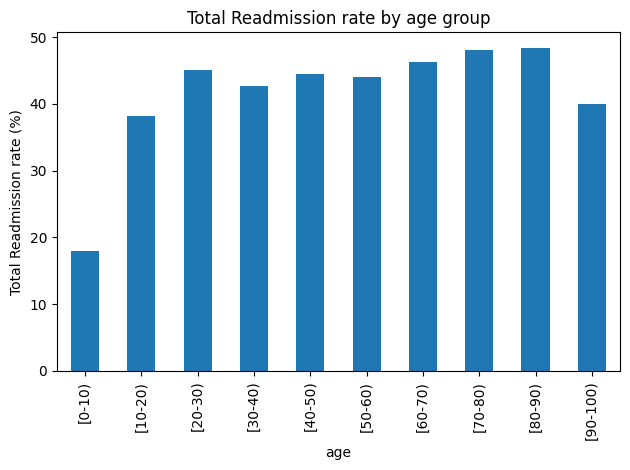

In [39]:
# Readmission references for both under and over 30-day windows.
query = '''
SELECT age,
       COUNT(*) AS encounters,
       SUM(1) FILTER (WHERE readmitted = '<30' OR readmitted = '>30'
                     ) AS readmitted_count,
       ROUND(
             SUM(1) FILTER (WHERE readmitted = '<30' OR readmitted = '>30') * 100.0 /
             COUNT(*),
       1) AS pct_readmitted_in_total
FROM diabetes_data
GROUP BY age
ORDER BY age;
'''

print(pd.read_sql(query, conn))

result = pd.read_sql(query, conn)
result.plot(x="age", y="pct_readmitted_in_total", kind="bar", legend=False)
plt.ylabel("Total Readmission rate (%)")
plt.title("Total Readmission rate by age group")
plt.tight_layout()
plt.show()

Notes:
1. 54,864 encounters (about 54%) were not readmitted.
2. Most age group has similar percentage of readmission which is about 46%.
3. It also suggests children under 10 years old had the lowest rate, but the group is small (161 encounters).

    time_in_hospital  encounters  pct_readmitted_30d
0                  1       14208                 8.2
1                  2       17224                 9.9
2                  3       17756                10.7
3                  4       13924                11.8
4                  5        9966                12.0
5                  6        7539                12.6
6                  7        5859                12.8
7                  8        4391                14.2
8                  9        3002                13.7
9                 10        2342                14.3
10                11        1855                10.5
11                12        1448                13.3
12                13        1210                12.3
13                14        1042                13.0
Index(['time_in_hospital', 'encounters', 'pct_readmitted_30d'], dtype='object')


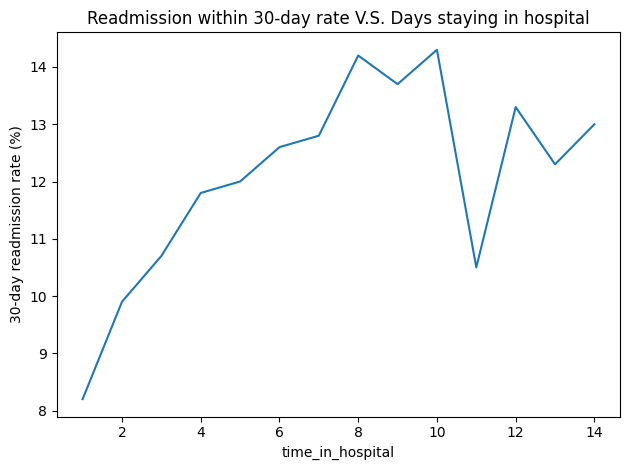

In [40]:
# Examines whether a longer hospital stay is associated with patient readmission.
query = '''
SELECT
       time_in_hospital,
       COUNT(*) AS encounters,
       ROUND(SUM(1)
             FILTER (WHERE readmitted = '<30') * 100.0 /
             COUNT(*),
       1) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY time_in_hospital
ORDER BY time_in_hospital
'''

print(pd.read_sql(query, conn))

result = pd.read_sql(query, conn)
print(result.columns)
result.plot(x="time_in_hospital", y="pct_readmitted_30d", kind="line", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("Readmission within 30-day rate V.S. Days staying in hospital")
plt.tight_layout()
plt.show()

Notes:
1. This outcome indicates encounters who stay in hospital longer are more likely readmitted in 30 days.
2. Noticed the percentage drops rapidly by day 11. Adding 'COUNT(*) AS encounters' to check out whether the percentage of readmission within 30-day is associated with the number of encounters.

In [41]:
# Examines if the number of earlier inpatient visits (number_inpatient) relates to readmission.
query = '''
SELECT number_inpatient,
       COUNT(*) AS encounters,
       ROUND(100.0 *
             COUNT(*) FILTER (WHERE readmitted = '<30') /
             COUNT(*),
       1) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY number_inpatient
HAVING COUNT(*) >= 100
ORDER BY number_inpatient;
'''

print(pd.read_sql(query, conn))

   number_inpatient  encounters  pct_readmitted_30d
0                 0       67630                 8.4
1                 1       19521                12.9
2                 2        7566                17.4
3                 3        3411                20.3
4                 4        1622                23.6
5                 5         812                31.4
6                 6         480                34.6
7                 7         268                35.4
8                 8         151                44.4
9                 9         111                42.3


Higher number of inpatient visits and lower encounters relate to higher percentage of readmission within 30 days.

In [42]:
# Determinate whether medical_specialty has the highest 30-day readmission rate.
query = '''
SELECT medical_specialty,
       COUNT(*) AS encounters,
       COUNT(*) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
       ROUND(100.0 *
             COUNT(*) FILTER (WHERE readmitted = '<30') /
             COUNT(*),
       1) AS pct_readmitted_30d
FROM diabetes_data
WHERE medical_specialty != '?'
GROUP BY medical_specialty
HAVING COUNT(*) >= 500
ORDER BY pct_readmitted_30d DESC;
'''

print(pd.read_sql(query, conn))

                  medical_specialty  encounters  readmitted_30d  \
0                        Nephrology        1613             248   
1                  Surgery-Vascular         533              74   
2                        Psychiatry         854             104   
3            Family/GeneralPractice        7440             883   
4                  InternalMedicine       14635            1646   
5                  Emergency/Trauma        7565             846   
6                   Surgery-General        3099             342   
7                       Pulmonology         871              96   
8                  Gastroenterology         564              62   
9                       Orthopedics        1400             151   
10                          Urology         685              68   
11                      Radiologist        1140             103   
12                       Cardiology        5352             425   
13       Orthopedics-Reconstructive        1233              9

Nephrology category has the highest 30-day readmission rate.



  A1Cresult  encounters  readmitted_30d  pct_readmitted_30d
0      None       84748            9681                11.4
1        >7        3812             383                10.0
2        >8        8216             811                 9.9
3      Norm        4990             482                 9.7
Index(['A1Cresult', 'encounters', 'readmitted_30d', 'pct_readmitted_30d'], dtype='object')


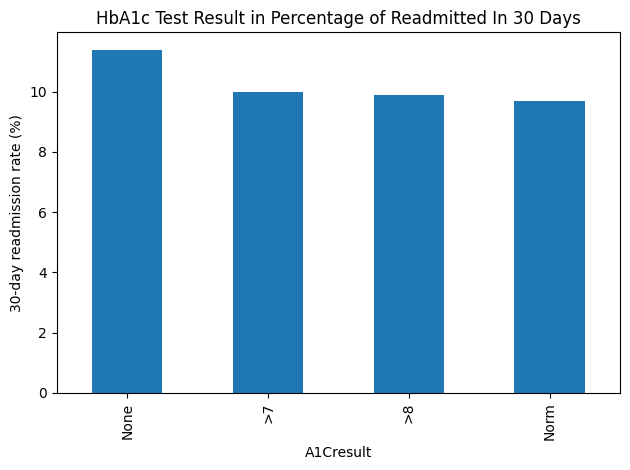

In [43]:
# Examines whether the HbA1c test relates to readmission.
query = '''
SELECT A1Cresult,
       COUNT(*) AS encounters,
       COUNT(*) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
       ROUND(100.0 *
             COUNT(*) FILTER (WHERE readmitted = '<30') /
             COUNT(*),
       1) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY A1Cresult
'''
print(pd.read_sql(query, conn))

result = pd.read_sql(query, conn)
print(result.columns)
result.plot(x="A1Cresult", y="pct_readmitted_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("HbA1c Test Result in Percentage of Readmitted In 30 Days")
plt.tight_layout()
plt.show()

Notes:
1. We can conclude that having an HbA1c test is associated with a lower likehood of 30-day readmission, as only 9% of encounters who received this text were readmitted within 30 dyas. Furthermore, encounters who did not take this test had a higher rate of readmission within 30 days. Moreover, the total number of readmitted encounters who did not receive an HbA1c test far exceeds the total number of readmitted encounters who did receive this test.


In [44]:
# Clean the data and note its limits
df = df.replace("?", pd.NA)
print(df.isna().sum().sort_values(ascending=False).head(10))
# Shows which columns have the most missing values.


weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
patient_nbr              0
dtype: int64


Indicating columns weihght, max_gul_serum, and A1Cresult have the most missing values.

In [45]:
# Check the IDS_mapping.csv file
df1 = pd.read_csv("IDS_mapping.csv")
df1.shape
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   admission_type_id  65 non-null     object
 1   description        62 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [46]:
# Find descriptions containing expired or hospice
filtered_df1 = df1[ # creates a new filtered subset dataframe by taking out rows out of df1 -- the IDS_mapping lookup table.
    df1["description"].str.contains(  # .str treats every row/entry in this column as string text
                                      # .contains(...) a pandas string method that checks if a specific word or pattern exists
                                      # inside each text row/entry.
        "expired|hospice",            # spaces matter, pandas will literally search for the phrase "expired " or "  Hospice".
        case=False,                   # search case-insensitive
        na=False                      # Tells pandas how to handle missing values like (NaN or empty cells) in this column.
                                      # treats any missing cell as a "False" (don't match this row), so the code doesn't crash.
    )
]
filtered_df1

,admission_type_id,description
20,11,Expired
22,13,Hospice / home
23,14,Hospice / medical facility
28,19,"Expired at home. Medicaid only, hospice."
29,20,"Expired in a medical facility. Medicaid only, ..."
30,21,"Expired, place unknown. Medicaid only, hospice."
66,26,Transfer from Hospice


Exclude these patients from readmission cohorts, since they will always count as "not readmitted", lowering readmission rates and misleading the final analysis result.

In [47]:
query = '''
SELECT 'hello' AS greeting,
       COUNT(*) AS encounters
FROM diabetes_data;
'''
print(pd.read_sql(query, conn))

  greeting  encounters
0    hello      101766


In [48]:
# Exclude these patients from readmission cohorts

query = '''
SELECT COUNT(*) AS encounters_to_remove
FROM diabetes_data
WHERE discharge_disposition_id IN (11, 13, 14, 19, 20 ,21);
'''

print(pd.read_sql(query, conn))

   encounters_to_remove
0                  2423


In [49]:
# compare the overall 30-day readmission rate before

# first line return a new column
# UNION ALL takes the results of two SELECT queries and stacks them together into one table. Keeping all rows.
# Plain UNION does the same but removes duplicates.
query = '''
SELECT 'all encounters' AS version,
       COUNT(*) AS encounters,
       ROUND(100.0 * COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data
UNION ALL
SELECT 'excluding expired/hospice',
       COUNT(*),
       ROUND(100.0 * COUNT(*) FILTER  (WHERE readmitted = '<30') / COUNT(*), 1)
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20, 21);
'''

print(pd.read_sql(query, conn))

                     version  encounters  pct_readmitted_30d
0             all encounters      101766                11.2
1  excluding expired/hospice       99343                11.4


Notes:
The number of encounters reduces from 101,766 to 99,343 (2,423 in difference), and the percentage of 30-day readmission rasies slightly from 11.2% to 11.4%.

In [50]:
# Rerun the analysis of readmission rate with age groups
query = '''
SELECT age,
       COUNT(*) AS encounters,
       COUNT(*) FILTER (WHERE readmitted = '<30') AS encounters_readmitted_30d,
       ROUND(100.0 * COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20, 21)
GROUP BY age
ORDER BY age;
'''

print(pd.read_sql(query, conn))

        age  encounters  encounters_readmitted_30d  pct_readmitted_30d
0    [0-10)         160                          3                 1.9
1   [10-20)         690                         40                 5.8
2   [20-30)        1649                        236                14.3
3   [30-40)        3764                        424                11.3
4   [40-50)        9607                       1024                10.7
5   [50-60)       17060                       1667                 9.8
6   [60-70)       22059                       2493                11.3
7   [70-80)       25331                       3054                12.1
8   [80-90)       16434                       2065                12.6
9  [90-100)        2589                        308                11.9


Notes:
In contrast, the 30-day readmission rates are gradually rasising a little bit after this exclusion, especially for elderly age groups ([80-90] rasies from 12.1% to 12.6%, and [90-100] rasies from 11.1% to 11.9%.

Summary:

Across all (101,766) hospital encounters, about 11% were readmitted within 30 days, and 35% were readmitted after 30 days.The overall readmission rate of all encounters is about 46%. The readmission rates were similar across adult age groups (about 10-12%) but were associated with the length of staying days, raising from 8.2% at day one to 14.3% at day ten. The relation between HbA1c test and readmission rate was low, since encounters with HbA1c test had a slightly lower percentage of 30-day readmission (about 10%) than those without (11.4%).